In [41]:
import sys
from pathlib import Path
import numpy as np
import yaml
import jax
import gc
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import EI.ei_unified as eu
from EI_baths.phase_map_plots import plot_maps, scan_maps
from EI_baths.fixed_baths import (
    plot_bz,
    plot_dispersion,
    plot_energy,
    plot_xi,
    solve_state,
    solve_teff,
)
from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter
import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
from EI.ei_anderson import solve_anderson

from utils.logger import logger, tqdm_bar
from utils.plotting_utils import Plotter, plot_cmap, format_ax, add_legend, plot_cmap, plot_phase_diag, color_map
from EI_baths.fixed_baths import k_path, take_path, color_line, solve_state, plot_dispersion


apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [42]:
from matplotlib.colors import SymLogNorm
import matplotlib.pyplot as plt
import colormaps as cmaps
import jax.numpy as jnp
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
from utils.cosmetics import SET1_LIST

In [43]:
import time
from dataclasses import replace
import EI.ei_cavity as cv
import EI.ei_ibz as ibz
with CFG.open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

md = cfg["model"]
eq = cfg["equilibrium"]
sc = cfg["scan"]
op = cfg["open_system"]
nk = md["nk"]
bp = md["band"]["pars"]
taeV = 0.1
bd = eu.tb_2d(nk["scan"], **bp)
p = eu.MFPars(**md["mean_field"])

s0 = eu.solve_eq(bd, p, **eq["initial"], **eq["solve"])
d0, m0 = max(abs(float(s0.d)), 1.0e-12), float(s0.m)
tc = float(eu.critical_temperature(bd, p, **eq["critical"]))
t1, t2 = 0.8 * tc, 0.2 * tc  # photon, phonon

kriticna temp bisekcija:   0%|          | 0/80 [00:00<?, ?it/s]

In [44]:
logger.info(f"Delta_0 = {d0} = {d0 *taeV/(8.617 * 1e-5)} K")
logger.info(f"m = {m0}")
logger.info(f"T_c = {tc} = {tc *taeV /(8.617 * 1e-5)} K")

[20:19:56] [INFO    ] Delta_0 = 0.14589107518462524 = 169.30611022934343 K
[20:19:56] [INFO    ] m = -0.8609816176022347
[20:19:56] [INFO    ] T_c = 0.08183893284742247 = 94.97381089407271 K


In [45]:
bc = op["bath"]
fn = getattr(pb, bc["rate"])
bq = dict(bc["pars"])
ov = bc["baths"]  # (photon, phonon)
gp, ph = (fn(t, bd.k, name=f"bath_{i + 1}", **{**bq, **o})
          for i, (t, o) in enumerate(zip((t1, t2), ov)))

gp0 = replace(gp, dip=0.0)
cb = cv.CavityBath(t=t1, w0=gp.w0, gam=gp.gam, ta=bp["ta"], tb=bp["tb"],
                   c=gp.cs, amp=gp.amp, a0=gp.a0)
ph0 = replace(ph, amp=0.0)  # zero phonons, pack still needs a grid bath

In [46]:
st = ej.mf_state(bd, p, d0, m0)
e = np.asarray(st.e)
up, dn = (np.asarray(z) for z in cv.local(st.e, st.u, st.v, jnp.asarray(bd.k), cv.stack((cb,))))

In [47]:
nq = bd.size
w = 1.0 / nq
rg = np.asarray(ej.dense_rates(st, (gp0, ph0)))
ra = np.asarray(ej.dense_rates(st, (cb, ph0)))
gin = rg[:nq, nq:].sum(axis=1) * w  # into alpha_k from all beta_k'
ain = ra[:nq, nq:].sum(axis=1) * w  # analytic: only k' = k
gaa = rg[:nq, :nq].sum(axis=1) * w  # intraband, grid only
ek = 0.5 * (e[0] - e[1]) / d0

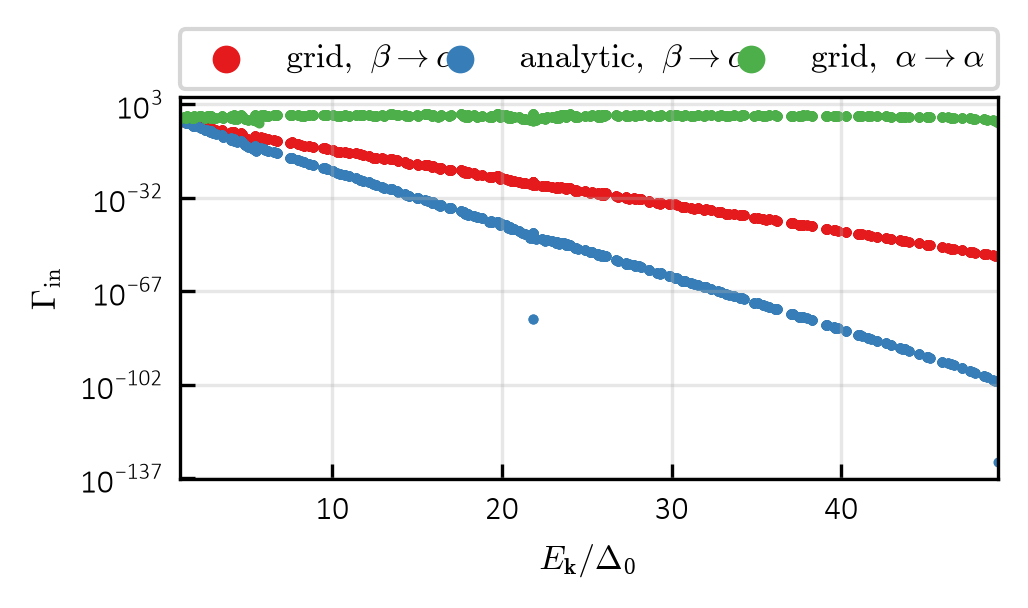

In [48]:
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
for i, (z, lb) in enumerate(((gin, r"$\mathrm{grid},\ \beta\to\alpha$"),
                             (ain, r"$\mathrm{analytic},\ \beta\to\alpha$"),
                             (gaa, r"$\mathrm{grid},\ \alpha\to\alpha$"))):
    ax.scatter(ek, z, s=2, color=SET1_LIST[i], label=lb, rasterized=True)
ax.set_yscale("log")
ax.set_xlim(ek.min(), ek.max())
ax.set_xlabel(r"$E_{\mathbf{k}}/\Delta_0$")
ax.set_ylabel(r"$\Gamma_{\mathrm{in}}$")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left",
          mode="expand", borderaxespad=0, ncol=3, markerscale=4)
ax.tick_params(which="both", direction="in")
plt.tight_layout()

In [49]:
se = eu.solve_eq(bd, p, t=t2, d=max(d0, 1.0e-3), m=m0, **{**eq["solve"], "prog": False})
kw = dict(mix=(0.5, 0.5, 0.1), tol=1.0e-4, nmax=5000, chk=50, prog=True, jtol=1.0e-1)
runs = {"A": (gp, ph), "B": (gp0, ph), "C": (cb, ph)}
sol = {}
for q, bb in runs.items():
    t0 = time.perf_counter()
    sol[q] = ej.solve_fixed(bd, p, se.n.copy(), bb, d=float(se.d), m=float(se.m), **kw)
    logger.info(f"{q}: d/d0 = {sol[q].d / d0:.5f}, m = {sol[q].m:.5f}, "
                f"err = {sol[q].err:.1e}, ok = {sol[q].ok}, t = {time.perf_counter() - t0:.1f} s")

Fixed EI JAX:   0%|          | 0/100 [00:00<?, ?it/s]

[20:19:57] [INFO    ] A: d/d0 = 0.75657, m = -0.86194, err = 8.6e-05, ok = True, t = 0.3 s


Fixed EI JAX:   0%|          | 0/100 [00:00<?, ?it/s]

[20:19:57] [INFO    ] B: d/d0 = 0.75657, m = -0.86194, err = 8.6e-05, ok = True, t = 0.3 s


Fixed EI JAX:   0%|          | 0/100 [00:00<?, ?it/s]

[20:19:57] [INFO    ] C: d/d0 = 0.79650, m = -0.86165, err = 6.6e-05, ok = True, t = 0.2 s


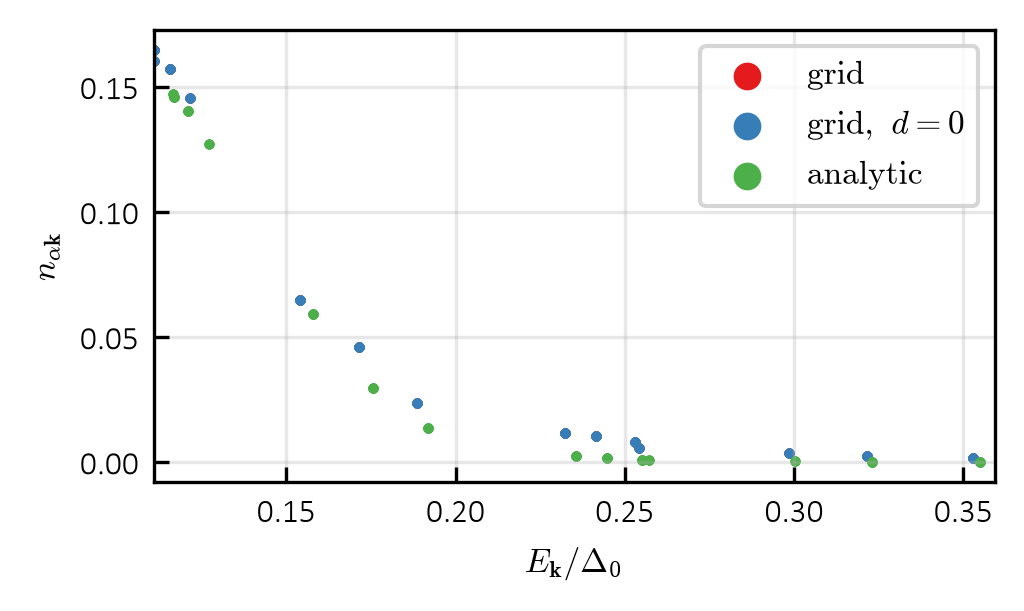

In [50]:
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
lbs = {"A": r"$\mathrm{grid}$", "B": r"$\mathrm{grid},\ d=0$", "C": r"$\mathrm{analytic}$"}
xs = []
for i, q in enumerate(runs):
    s_ = sol[q]
    x = 0.5 * (s_.st.e[0] - s_.st.e[1]) / d0
    xs.append(x * d0)
    ax.scatter(x * d0, s_.n[0], s=2, color=SET1_LIST[i], label=lbs[q], rasterized=True)
xs = np.concatenate(xs)
ax.set_xlim(xs.min(), xs.max()/20)
ax.set_xlabel(r"$E_{\mathbf{k}}/\Delta_0$")
ax.set_ylabel(r"$n_{\alpha\mathbf{k}}$")
ax.grid(alpha=0.3)
ax.legend(markerscale=4)
ax.tick_params(which="both", direction="in")
plt.tight_layout()

In [51]:
gw = (0.0, 2.0)  # s window
bi, ib = ibz.tb_2d_ibz(nk["scan"], **bp)

gp0, ph = (fn(t, ib.kf, name=f"bath_{i + 1}", **{**bq, **o})
           for i, (t, o) in enumerate(zip((t1, t2), ov)))
gp0 = replace(gp0, dip=0.0)

cl = 3945.0
cb = cv.CavityBath(t=t1, w0=gp0.w0, gam=gp0.gam, ta=bp["ta"], tb=bp["tb"],
                   c=cl, amp=gp0.amp * (cl / gp0.cs) ** 2, a0=gp0.a0)

In [52]:
si = eu.solve_eq(bi, p, t=t2, d=max(d0, 1.0e-3), m=m0, **{**eq["solve"], "prog": False})
kw = dict(mix=(0.5, 0.5, 0.1), tol=1.0e-6, nmax=5000, chk=50, prog=True, jtol=1.0e-1)

sol = {}
for q, bb in {"grid": (gp0, ph), "cav": (cb, ph)}.items():
    wb = ibz.WinBaths(bb, ib, *gw)
    sol[q] = ej.solve_fixed(bi, p, ibz.freeze(si.n, bi, p, wb), wb,
                            d=float(si.d), m=float(si.m), **kw)
    logger.info(f"{q}: d/d0 = {sol[q].d / d0:.5f}, m = {sol[q].m:.5f}, "
                f"err = {sol[q].err:.1e}, ok = {sol[q].ok}")

Fixed EI JAX:   0%|          | 0/100 [00:00<?, ?it/s]

[20:19:59] [INFO    ] grid: d/d0 = 0.74998, m = -0.86197, err = 5.8e-07, ok = True


Fixed EI JAX:   0%|          | 0/100 [00:00<?, ?it/s]

[20:19:59] [INFO    ] cav: d/d0 = 0.79347, m = -0.86166, err = 4.4e-07, ok = True


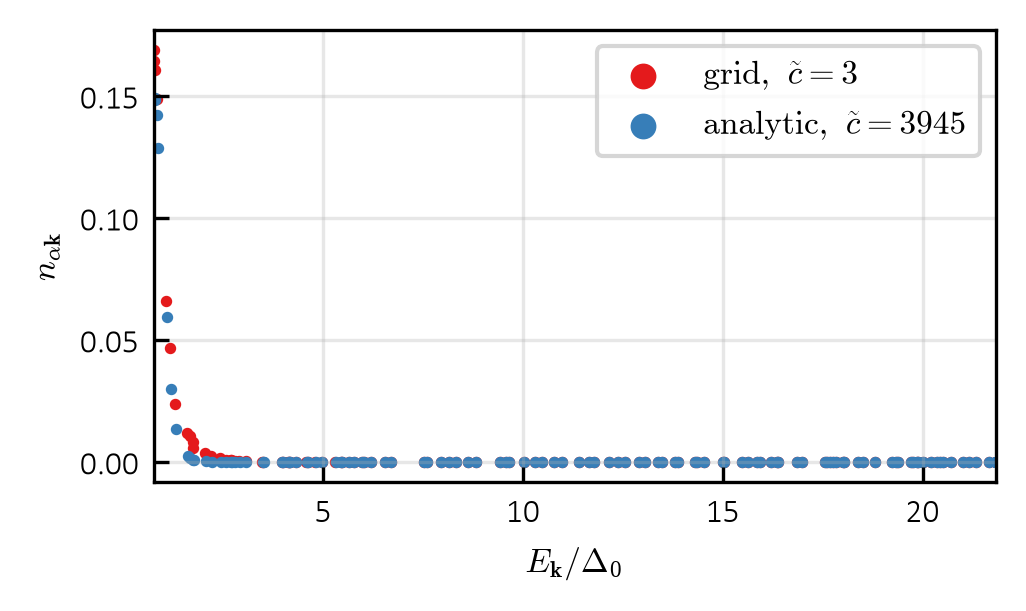

In [53]:
wi, _ = ibz.win_index(ib, *gw)
fig, ax = plt.subplots(figsize=(3.47412, 0.6 * 3.47412))
xs = []
for i, (q, lb) in enumerate((("grid", r"$\mathrm{grid},\ \tilde c=3$"),
                             ("cav", r"$\mathrm{analytic},\ \tilde c=3945$"))):
    s_ = sol[q]
    x = 0.5 * (s_.st.e[0] - s_.st.e[1])[wi] / d0
    xs.append(x)
    ax.scatter(x, s_.n[0][wi], s=3, color=SET1_LIST[i], label=lb, rasterized=True)
xs = np.concatenate(xs)
ax.set_xlim(xs.min(), xs.max())
ax.set_xlabel(r"$E_{\mathbf{k}}/\Delta_0$")
ax.set_ylabel(r"$n_{\alpha\mathbf{k}}$")
ax.grid(alpha=0.3)
ax.legend(markerscale=3)
ax.tick_params(which="both", direction="in")
plt.tight_layout()

In [54]:
t1r = np.linspace(0.01, 2.5, 10)  # T1 / Tc, photons
t2r = np.linspace(0.01, 1.5, 10)  # T2 / Tc, phonons
ds, nw = 1.0e-3, 200              # gap floor, warm up iterations
kf = {**kw, "prog": False, "pc": True}

mg = lambda a, b: (replace(gp0, t=a), replace(ph, t=b))  # grid photons, c = 3
mc = lambda a, b: (replace(cb, t=a), replace(ph, t=b))   # analytic, c = 3945

In [55]:
def sweep(mk):
    """Gap and imbalance on the (T2, T1) grid, rows = T2."""
    dm = np.full((t2r.size, t1r.size), np.nan)
    mm = np.full_like(dm, np.nan)
    ok = np.zeros(dm.shape, dtype=bool)
    wb = ibz.WinBaths(mk(tc, tc), ib, *gw)
    s0 = (ibz.freeze(si.n, bi, p, wb), float(si.d), float(si.m))
    for i in tqdm(range(t2r.size), desc="T2 sweep"):
        sv = s0
        for j in range(t1r.size):
            wb = ibz.WinBaths(mk(t1r[j] * tc, t2r[i] * tc), ib, *gw)
            n0, dv, mv = sv
            sn = ej.solve_fixed(bi, p, n0.copy(), wb, d=max(abs(dv), ds), m=mv, **kf)
            if abs(float(sn.d)) < ds:  # retry from a warm up
                w0_ = ej.solve_fixed(bi, p, sn.n.copy(), wb, d=ds, m=float(sn.m),
                                     **{**kf, "nmax": nw})
                sn = ej.solve_fixed(bi, p, w0_.n.copy(), wb, d=float(w0_.d),
                                    m=float(w0_.m), **kf)
            dm[i, j], mm[i, j], ok[i, j] = sn.d, sn.m, bool(sn.ok)
            if np.isfinite(sn.err):
                sv = (sn.n, float(sn.d), float(sn.m))
                if j == 0:
                    s0 = sv  # next row starts here
    return dm, mm, ok

T2 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T2 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

unconverged grid: 3  analytic: 9


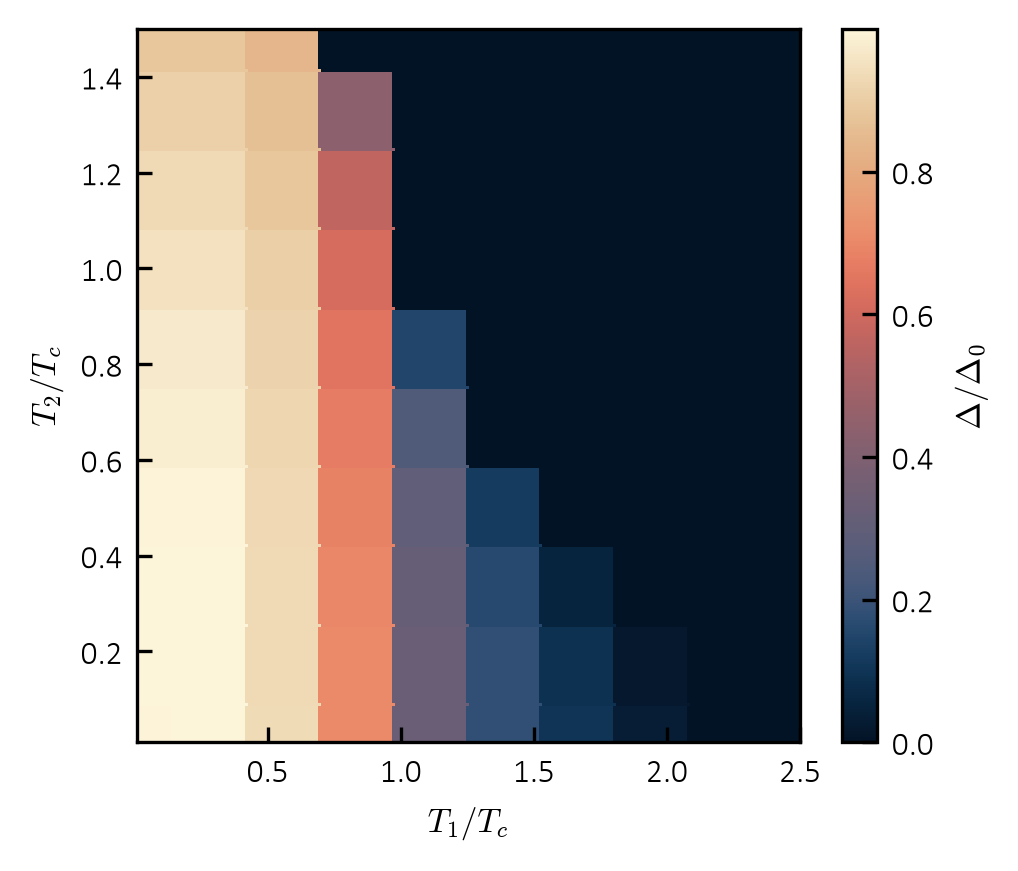

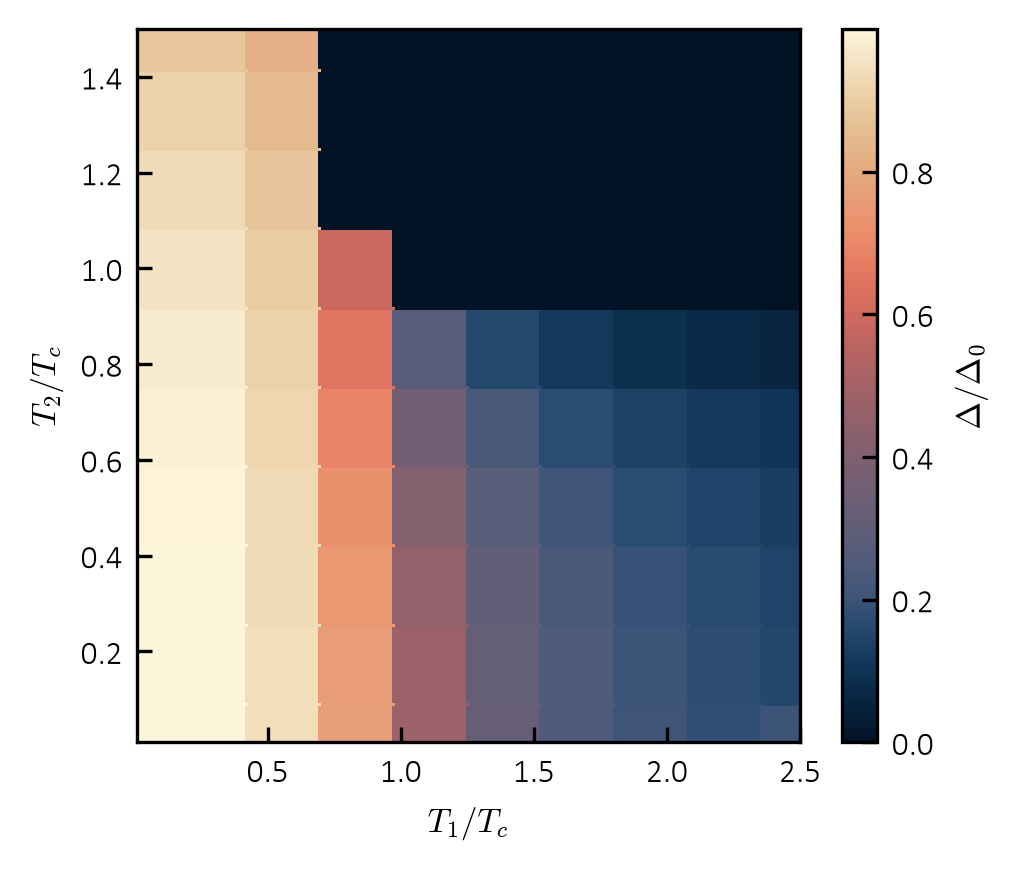

In [56]:
dg, mgm, okg = sweep(mg)
da, mam, oka = sweep(mc)
print("unconverged grid:", (~okg).sum(), " analytic:", (~oka).sum())

fg, _ = plot_cmap(t1r, t2r, dg / d0, r"$\Delta/\Delta_0$", pt=pt)
fa, _ = plot_cmap(t1r, t2r, da / d0, r"$\Delta/\Delta_0$", pt=pt)
# fg.savefig(FIG_PATH + "gap_map_grid_c3.pdf", bbox_inches="tight")
# fa.savefig(FIG_PATH + "gap_map_cav_c3945.pdf", bbox_inches="tight")